# Climate change as a change in regime frequency: a forced Lorenz system

**Author:** Julien Emile-Geay
**Date:** Nov 19 2026

_Description:_ Revisits the argument of [Palmer (1993)](https://doi.org/10.1002/j.1477-8696.1993.tb05802.x) and [Palmer (1999)](https://doi.org/10.1175/1520-0442(1999)012<0575:ANDPOC>2.0.CO;2): in a nonlinear system with quasi-stationary regimes, a weak external forcing changes mainly *how often* each regime is visited, and much less the regimes themselves. The toy model is the `Lorenz63` critter with a constant forcing of magnitude $f_0$ and direction $\theta$ in the $(x, y)$ plane. Adapted from Lab 10 of GEOL 351 (USC).

_ClimateCritters functionality used:_
- the `Lorenz63` critter, with the forcing attached via `Model.register_forcing` (additive state forcing on the tendencies), so the model code is left untouched;
- `cc.utils.forcing.create_constant_forcing` to build the forcing components;
- the fixed-step `rk4` solver of `Model.integrate`;
- `Output.to_pyleo` and pyleoclim's `Series.filter` to separate "weather" from "climate".

The forced system is

$$
\begin{aligned}
\dot{x} & = \sigma(y-x) + f_0 \cos\theta\\
\dot{y} & = \rho x - y - xz + f_0 \sin\theta\\
\dot{z} & = -\beta z + xy
\end{aligned}
$$

with the classic parameters $\sigma=10$, $\rho=28$, $\beta=8/3$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns          # also registers the 'mako' colormaps
from mpl_toolkits.axes_grid1 import make_axes_locatable
import climatecritters as cc
from climatecritters.model_critters.lorenz import Lorenz63
from climatecritters.utils.forcing import create_constant_forcing

sigma, rho, beta = 10.0, 28.0, 8 / 3
xC = np.sqrt(beta * (rho - 1))          # C+ = (xC, xC, rho-1), C- = (-xC, -xC, rho-1)

# Same figure style as the Strogatz §9.5 notebook
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'mathtext.fontset': 'custom', 'mathtext.rm': 'Arial', 'mathtext.it': 'Arial:italic',
    'mathtext.bf': 'Arial:bold', 'mathtext.cal': 'Arial',
    'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'figure.titlesize': 14, 'figure.titleweight': 'bold',
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 1,
    'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '0.85', 'grid.linestyle': ':', 'grid.linewidth': 0.8,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.major.width': 1, 'ytick.major.width': 1,
    'legend.frameon': False,
    'figure.dpi': 110,
})
BLUE, RED, ORANGE, INK = '#2c7bb6', '#c0182b', '#f28e2b', '0.15'

## Attaching the forcing

The `Lorenz63` critter has no forcing term, and it doesn't need one. `register_forcing` with `attachment_style='additive'` and `timing='pre'` adds a time series to the tendency $\dot{x}$ (or $\dot{y}$) inside the right-hand side. Here both time series are constants, built with `create_constant_forcing`. Any `cc.Forcing` would do, so the same code handles a ramped or oscillating forcing.

In [2]:
def forced_lorenz(f0=0.0, theta=0.0):
    '''Lorenz63 critter with a constant forcing f0 (cos theta, sin theta) on (dx/dt, dy/dt). theta in degrees.'''
    model = Lorenz63(sigma=sigma, rho=rho, beta=beta)
    if f0 != 0:
        th = np.deg2rad(theta)
        model.register_forcing('x', create_constant_forcing(f0 * np.cos(th)), 'additive', timing='pre')
        model.register_forcing('y', create_constant_forcing(f0 * np.sin(th)), 'additive', timing='pre')
    return model

## Weather and climate in the unforced system

We integrate the system with the fixed-step `rk4` solver ($\Delta t = 0.01$), discard a spin-up of 10 time units by passing `output_time` to `integrate`, and export the result to pyleoclim. The trajectory orbits $C^+$ or $C^-$ ($x, y \approx \pm 8.5$) for a while, then switches to the other lobe at irregular intervals. The fast orbits are the "weather". The slow alternation between the two lobes, or *regimes*, is the "climate". To isolate it, we apply a zero-phase Butterworth lowpass filter (`Series.filter`) that removes time scales shorter than 2 time units, about three orbits around $C^\pm$.

In [3]:
dt, t_spin = 0.01, 10.0
y0 = [0.1, -0.1, 1.0]
cutoff = 2.0          # lowpass cutoff scale, in model time units

def spun_up(T):
    '''integrate() arguments for T time units after a spin-up of t_spin (output_time drops the spin-up).'''
    return dict(t_span=(0, t_spin + T), y0=y0, method='rk4', dt=dt, kwargs={'si': dt},
                output_time=np.arange(t_spin, t_spin + T + dt / 2, dt))

def climate(out, var):
    '''Raw and lowpass-filtered ("climate") versions of a variable, as pyleoclim Series.'''
    ts = out.to_pyleo(var)
    tf = ts.filter(cutoff_scale=cutoff)
    # drop 5 time units at each end, where the zero-phase filter has edge effects
    inner = [tf.time[0] + 5, tf.time[-1] - 5]
    return ts.slice(inner), tf.slice(inner)

out0 = forced_lorenz().integrate(**spun_up(1000.0))
ts_x, tsf_x = climate(out0, 'x')
ts_z, tsf_z = climate(out0, 'z')

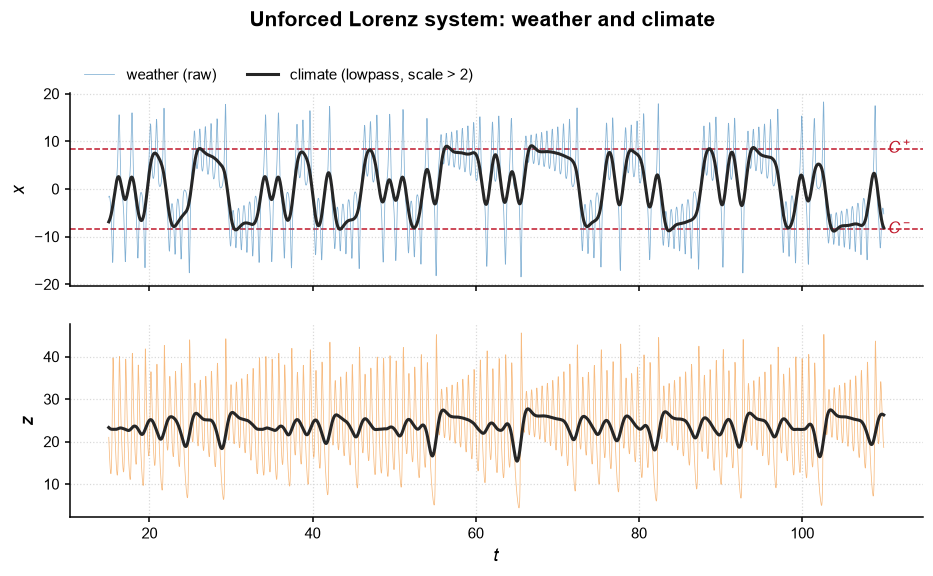

In [4]:
# Output.to_pyleo labels time as 'years CE' (pyleoclim's default; see #53). Lorenz time is
# dimensionless, so we set the axis label ourselves.
win = [10, 110]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, raw, filt, var, c in [(axes[0], ts_x, tsf_x, 'x', BLUE), (axes[1], ts_z, tsf_z, 'z', ORANGE)]:
    r, f = raw.slice(win), filt.slice(win)
    ax.plot(r.time, r.value, color=c, lw=0.5, alpha=0.6, label='weather (raw)')
    ax.plot(f.time, f.value, color=INK, lw=2, label=f'climate (lowpass, scale > {cutoff:g})')
    ax.set_ylabel(f'${var}$')
for sgn in (1, -1):
    axes[0].axhline(sgn * xC, color=RED, lw=1, ls='--', zorder=0)
axes[0].text(win[1] + 0.5, xC, '$C^+$', color=RED, va='center', fontweight='bold')
axes[0].text(win[1] + 0.5, -xC, '$C^-$', color=RED, va='center', fontweight='bold')
axes[0].legend(loc='upper left', ncol=2, bbox_to_anchor=(0, 1.2))
axes[1].set_xlabel('$t$')
fig.suptitle('Unforced Lorenz system: weather and climate', y=1.03)
plt.show()

$y$ behaves almost exactly like $x$, so we don't show it. We show the distribution of the filtered climate states in the $(x, y)$ plane as a hexagonal 2D histogram, with marginal histograms. The states lie close to the diagonal, because on time scales longer than $1/\sigma$ the first equation forces $x$ to follow $y$: after filtering, their correlation is 0.99. The distribution is bimodal. It is also symmetric: each regime is visited half of the time. The two maxima lie near $C^+$ and $C^-$ (yellow), but not exactly on them, because the trajectory never actually sits at $C^\pm$ and the lowpass filter pulls the states toward the origin.

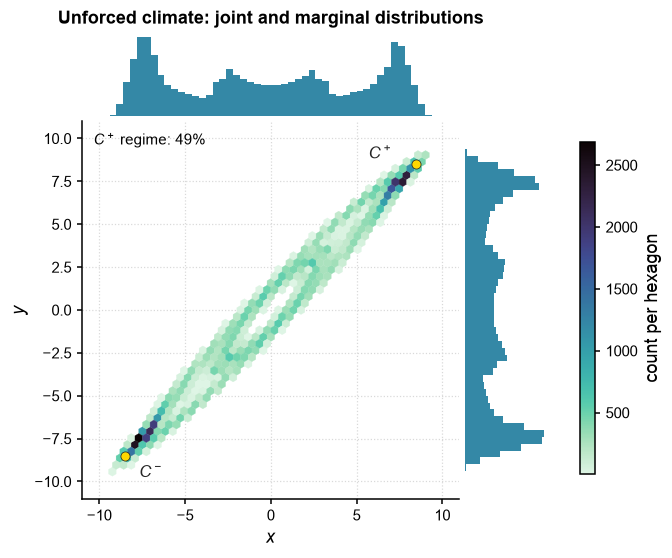

In [5]:
def climate_xy(out):
    '''Filtered x and y of a run.'''
    return climate(out, 'x')[1].value, climate(out, 'y')[1].value

HEX = dict(gridsize=50, extent=(-11, 11, -11, 11), mincnt=1, cmap='mako_r', linewidths=0.2)
HIST = dict(bins=np.linspace(-11, 11, 56), density=True)
MARG = plt.get_cmap('mako_r')(0.45)      # marginal histograms, in the hexbin colormap

def plot_pdf(xf, yf, ax, f0=0.0, theta=0.0, ref=None, title=None):
    '''Hexbin histogram of the climate states in the (x, y) plane, with marginal histograms,
    C+/-, and the forcing vector. `ref` = (x, y) of a reference run, drawn as a step line on the marginals.'''
    hb = ax.hexbin(xf, yf, **HEX)
    div = make_axes_locatable(ax)
    ax_x = div.append_axes('top', size='22%', pad=0.05, sharex=ax)
    ax_y = div.append_axes('right', size='22%', pad=0.05, sharey=ax)
    ax_x.hist(xf, color=MARG, **HIST)
    ax_y.hist(yf, color=MARG, orientation='horizontal', **HIST)
    if ref is not None:
        ax_x.hist(ref[0], histtype='step', color=INK, lw=1, **HIST)
        ax_y.hist(ref[1], histtype='step', color=INK, lw=1, orientation='horizontal', **HIST)
    for a in (ax_x, ax_y):
        a.axis('off')
    for sgn, lab, dx, dy in [(1, '$C^+$', -2.8, 0.3), (-1, '$C^-$', 0.8, -1.3)]:
        ax.plot(sgn * xC, sgn * xC, 'o', color='gold', mec=INK, mew=0.5, ms=6, zorder=5)
        ax.text(sgn * xC + dx, sgn * xC + dy, lab, color=INK, fontweight='bold', zorder=6)
    if f0:
        th = np.deg2rad(theta)
        L = 2 * f0 if f0 < 5 else f0            # arrow length (scaled for visibility)
        ax.annotate('', xy=(L * np.cos(th), L * np.sin(th)), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='-|>', color=RED, lw=2.5, mutation_scale=18))
    frac = (xf > 0).mean()
    ax.text(0.03, 0.97, f'$C^+$ regime: {100 * frac:.0f}%', transform=ax.transAxes,
            ha='left', va='top', fontsize=10)
    ax.set_xlim(-11, 11); ax.set_ylim(-11, 11); ax.set_aspect('equal')
    ax.set_xlabel('$x$'); ax.set_ylabel('$y$')
    ax_x.set_title(title if title else
                   (f'$f_0={f0:g}$, $\\theta={theta:g}°$' if f0 else 'unforced'))
    return hb

def add_colorbar(fig, hb, rect=(0.93, 0.2, 0.015, 0.55)):
    fig.colorbar(hb, cax=fig.add_axes(rect), label='count per hexagon')

xf0, yf0 = climate_xy(out0)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
hb = plot_pdf(xf0, yf0, ax, title='Unforced climate: joint and marginal distributions')
add_colorbar(fig, hb, rect=(0.95, 0.15, 0.025, 0.55))
plt.show()

## Climate change in the Lorenz system

We now apply a forcing of magnitude $f_0 = 2.5$ (about 10% of the typical tendency) in four directions, as in Palmer (1993), and compare the climate distributions. The red arrow shows the direction of the forcing, and the black step lines on the marginal histograms show the unforced distribution. Each run covers 1000 time units, so the integrations take about 10 s.

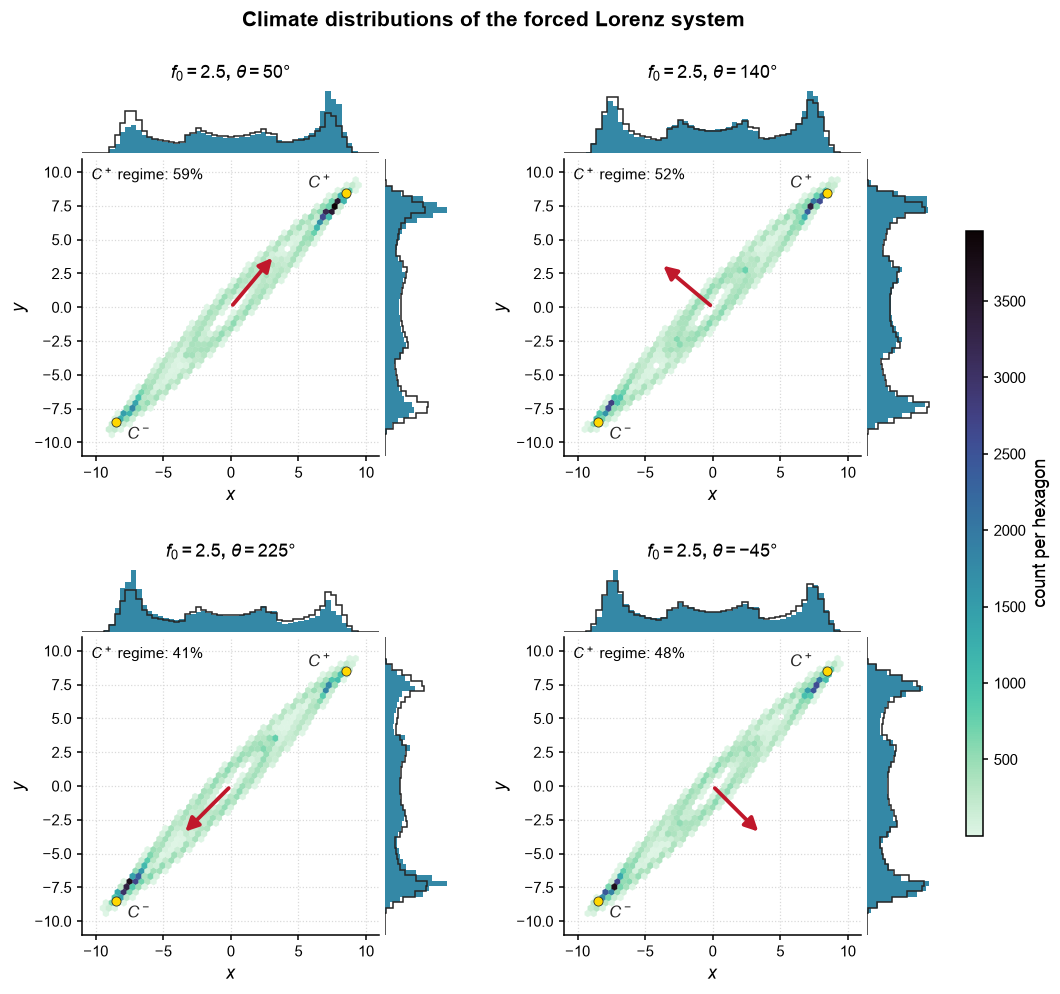

In [6]:
cases = [(2.5, 50), (2.5, 140), (2.5, 225), (2.5, -45)]
pdfs = {(f0, theta): climate_xy(forced_lorenz(f0, theta).integrate(**spun_up(1000.0)))
        for f0, theta in cases}

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
hbs = [plot_pdf(xf, yf, ax, *key, ref=(xf0, yf0))
       for ax, (key, (xf, yf)) in zip(axes.flat, pdfs.items())]
vmax = max(hb.get_array().max() for hb in hbs)    # same color scale in every panel
for hb in hbs:
    hb.set_clim(1, vmax)
fig.subplots_adjust(hspace=0.3, wspace=0.3, right=0.9)
add_colorbar(fig, hbs[0])
fig.suptitle('Climate distributions of the forced Lorenz system', y=0.95)
plt.show()

Forcing toward the first quadrant ($\theta = 50°$) favors the $C^+$ regime, and forcing toward the third quadrant ($\theta = 225°$) favors $C^-$, as one might expect. The other two cases, with forcings perpendicular to the line joining $C^-$ and $C^+$, have a weak response. In all cases the two maxima stay close to where they were. The forcing redistributes probability between regimes much more than it moves them. With 1000 time units per run, though, differences of a few percent are within sampling error (see below).

## Quantifying Palmer's principles

Palmer (1999) states two principles: _"First, the response to a forcing will be manifest primarily in terms of changes to the residence frequency associated with the quasi-stationary regimes. Second, the [...] structures of these regimes will be relatively insensitive to the forcing (within limits)."_

To test both, we sweep $\theta$ every 30° for $f_0 = 2.5$ and $f_0 = 5$, and track two numbers for each run:
1. the **residence frequency** of the $C^+$ regime, i.e. the fraction of time with filtered $x>0$;
2. the **regime centroid**, i.e. the mean filtered $(x, y)$ over the time spent in each regime.

Short runs have large sampling errors, because the regime switches are irregular. We therefore integrate 3000 time units per run and estimate a standard error from 10 consecutive blocks. The sweep takes about 3 minutes.

In [7]:
thetas = np.arange(0, 360, 30)
amps = [2.5, 5.0]
T_sweep, n_blocks = 3000.0, 10

def regime_stats(f0, theta):
    xf, yf = climate_xy(forced_lorenz(f0, theta).integrate(**spun_up(T_sweep)))
    up = xf > 0
    blocks = np.array_split(up, n_blocks)
    frac = up.mean()
    se = np.std([b.mean() for b in blocks], ddof=1) / np.sqrt(n_blocks)
    cen_p = np.array([xf[up].mean(), yf[up].mean()])
    cen_m = np.array([xf[~up].mean(), yf[~up].mean()])
    return dict(frac=frac, se=se, cen_p=cen_p, cen_m=cen_m)

stats0 = regime_stats(0.0, 0.0)
sweep = {f0: [regime_stats(f0, th) for th in thetas] for f0 in amps}
print(f"unforced: C+ residence = {stats0['frac']:.3f} ± {stats0['se']:.3f}")

unforced: C+ residence = 0.499 ± 0.008


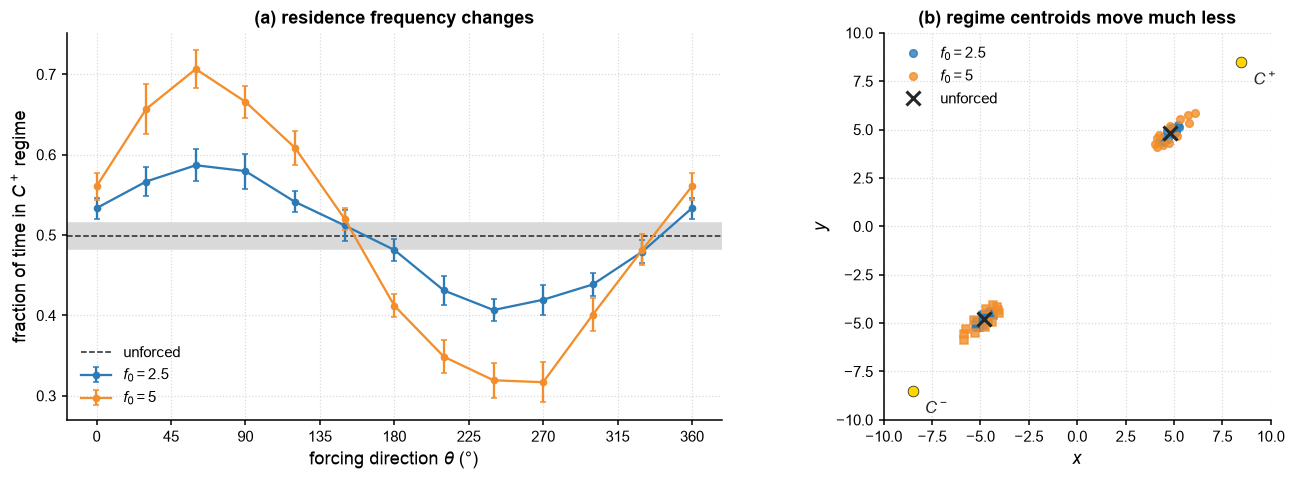

f0 = 2.5: C+ residence in [0.41, 0.59] (max relative change 18%); C+ centroid moves by at most 0.73 (11% of its distance to the origin, 6.8)
f0 = 5: C+ residence in [0.32, 0.71] (max relative change 42%); C+ centroid moves by at most 1.65 (24% of its distance to the origin, 6.8)
direction of maximum C+ response: {2.5: np.int64(60), 5.0: np.int64(60)}


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
th_closed = np.append(thetas, 360)
colors = {2.5: BLUE, 5.0: ORANGE}

# (a) residence frequency
ax1.axhline(stats0['frac'], color=INK, lw=1, ls='--', label='unforced')
ax1.axhspan(stats0['frac'] - 2 * stats0['se'], stats0['frac'] + 2 * stats0['se'],
            color='0.85', zorder=0)
for f0 in amps:
    frac = np.array([s['frac'] for s in sweep[f0]])
    se = np.array([s['se'] for s in sweep[f0]])
    ax1.errorbar(th_closed, np.append(frac, frac[0]), yerr=2 * np.append(se, se[0]),
                 color=colors[f0], marker='o', ms=4, capsize=2, label=f'$f_0={f0:g}$')
ax1.set_xticks(np.arange(0, 361, 45))
ax1.set_xlabel(r'forcing direction $\theta$ (°)')
ax1.set_ylabel('fraction of time in $C^+$ regime')
ax1.legend(loc='lower left')
ax1.set_title('(a) residence frequency changes')

# (b) regime centroids
for f0 in amps:
    for key, mk in [('cen_p', 'o'), ('cen_m', 's')]:
        c = np.array([s[key] for s in sweep[f0]])
        ax2.plot(c[:, 0], c[:, 1], mk, color=colors[f0], ms=5, alpha=0.8,
                 label=f'$f_0={f0:g}$' if key == 'cen_p' else None)
for key in ('cen_p', 'cen_m'):
    ax2.plot(*stats0[key], 'x', color=INK, ms=9, mew=2,
             label='unforced' if key == 'cen_p' else None)
for sgn, lab in [(1, '$C^+$'), (-1, '$C^-$')]:
    ax2.plot(sgn * xC, sgn * xC, 'o', color='gold', mec=INK, mew=0.5, ms=7)
    ax2.text(sgn * xC + 0.6, sgn * xC - 1.2, lab, color=INK, fontweight='bold')
ax2.set_xlim(-10, 10); ax2.set_ylim(-10, 10); ax2.set_aspect('equal')
ax2.set_xlabel('$x$'); ax2.set_ylabel('$y$')
ax2.legend(loc='upper left')
ax2.set_title('(b) regime centroids move much less')

fig.tight_layout()
plt.savefig('../figures/Lorenz63_forced_regimes.pdf', dpi=300, bbox_inches='tight')
plt.show()

r0 = np.linalg.norm(stats0['cen_p'])
for f0 in amps:
    frac = np.array([s['frac'] for s in sweep[f0]])
    dfrac = np.abs(frac - stats0['frac']).max() / stats0['frac']
    shift = np.array([np.linalg.norm(s['cen_p'] - stats0['cen_p']) for s in sweep[f0]])
    print(f"f0 = {f0:g}: C+ residence in [{frac.min():.2f}, {frac.max():.2f}] (max relative change {100 * dfrac:.0f}%); "
          f"C+ centroid moves by at most {shift.max():.2f} ({100 * shift.max() / r0:.0f}% of its distance to the origin, {r0:.1f})")
th_max = {f0: thetas[np.argmax([s['frac'] for s in sweep[f0]])] for f0 in amps}
print('direction of maximum C+ response:', th_max)

**Forced regimes.** (a) Fraction of time spent in the $C^+$ regime as a function of the forcing direction, with $\pm2$ standard errors. The grey band is the unforced value $\pm2$ standard errors. (b) Mean climate state within each regime (circles: $C^+$, squares: $C^-$) for every forcing in the sweep, compared with the unforced centroids (crosses) and the fixed points $C^\pm$ (gold).

The residence frequency responds strongly and smoothly to the forcing, roughly as a sinusoid in $\theta$. Its amplitude grows with $f_0$: up to 18% of the unforced value for $f_0=2.5$, and up to 42% for $f_0=5$. The regime centroids shift too, mostly along the diagonal, but by only about 11% ($f_0=2.5$) and 24% ($f_0=5$) of their distance from the origin. The response appears mainly as a change in residence frequency, and only secondarily as a change in the regimes themselves, as Palmer argued. The maximum response is near $\theta \approx 60°$, slightly anticlockwise of the $C^+$ direction (45°). Consequently, a forcing at $\theta = 135°$, perpendicular to that direction, still slightly favors $C^+$.

The second principle holds only "within limits": both effects grow with $f_0$. For much larger forcings (try $f_0 = 25$ with `run`), the attractor itself is deformed and can collapse onto a single fixed point.

**Implication.** If the climate system behaves this way, climate change shows up first as a change in the frequency of familiar weather regimes, not as new regimes. To detect it, one should monitor how often known regimes occur, rather than look for unprecedented states.

## References

- Lorenz, E. N., 1963: Deterministic nonperiodic flow. *J. Atmos. Sci.*, 20, 130–141, [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2).
- Palmer, T. N., 1993: A nonlinear dynamical perspective on climate change. *Weather*, 48, 314–326, [doi:10.1002/j.1477-8696.1993.tb05802.x](https://doi.org/10.1002/j.1477-8696.1993.tb05802.x).
- Palmer, T. N., 1999: A nonlinear dynamical perspective on climate prediction. *J. Climate*, 12, 575–591, [doi:10.1175/1520-0442(1999)012<0575:ANDPOC>2.0.CO;2](https://doi.org/10.1175/1520-0442(1999)012<0575:ANDPOC>2.0.CO;2).